# Modelos Simples | Modelo #3 - Splines

Este notebook estima a superfície de volatilidade implícita (IVS) usando Splines B-cúbicas (SplineTransformer) com RidgeCV em scikit-learn, com e sem interações m×T.

Autor: Sérgio Sobral  
Data: 09/09/2025

Importação de Bibliotecas

In [1]:
import os
import json
import joblib
from datetime import datetime, timezone
import numpy as np
import pandas as pd
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, SplineTransformer
from sklearn.linear_model import RidgeCV
from typing import Optional, Sequence, Iterable, Tuple
from sklearn.base import BaseEstimator, TransformerMixin

from __future__ import annotations

Designações Centrais e Caminhos

In [2]:
# Designações Centrais e Caminhos
DIR_TRATADOS = "02. Dados/02. Dados Tratados/"
DIR_RESULTADOS = "04. Resultados/03. Modelo #3 - Splines/"
DIR_GRAFICOS = "03. Output/01. Gráficos/06. Modelo #3 - Splines/"
DIR_TABELAS = "03. Output/02. Tabelas/03. Modelo #3 - Splines/"

# Criar diretório de gráficos/tabelas/resultados se não existir
os.makedirs(DIR_GRAFICOS, exist_ok=True)
os.makedirs(DIR_RESULTADOS, exist_ok=True)
os.makedirs(DIR_TABELAS, exist_ok=True)

# Ficheiros de input
ficheiro_universo        = os.path.join(DIR_TRATADOS, "Universo_Modelizacao_v1.00.parquet")
ficheiro_inner_train     = os.path.join(DIR_TRATADOS, "df_inner_train.parquet")
ficheiro_inner_tunning   = os.path.join(DIR_TRATADOS, "df_inner_tunning.parquet")
ficheiro_train_full      = os.path.join(DIR_TRATADOS, "df_train_full.parquet")
ficheiro_test_puro       = os.path.join(DIR_TRATADOS, "df_test_puro.parquet")

# Config
FEATURES = ("log_moneyness", "T")
TARGET = "iv_teorica"

# Save Models (nomes finais)
MODEL_PATH_INNER = os.path.join(DIR_RESULTADOS, "03. Splines_model_inner.joblib")
META_PATH_INNER  = os.path.join(DIR_RESULTADOS, "03. Splines_model_inner.meta.json")

MODEL_PATH_FINAL = os.path.join(DIR_RESULTADOS, "03. Splines_model.joblib")
META_PATH_FINAL  = os.path.join(DIR_RESULTADOS, "03. Splines_model.meta.json")

Funções Auxiliares

Palete de Cores:
azul1: #11469b
azul2: #2063c0
azul3: #5a90e7
cinza1: #777777
cinza2: #AAAAAA
cinza3: #bbbbbb
preto: #000000
branco: #ffffff

Estilos de Linha:
contínua: -
tracejada: --
ponto-traço: -.
pontilhada: :
contínua2: -
tracejada2: --
ponto-traço2: -.
pontilhada2: :


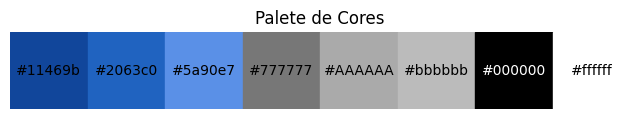

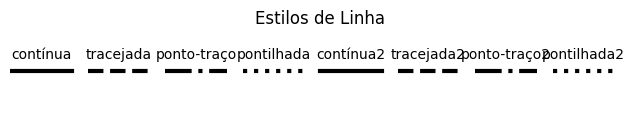

In [3]:
%run "01. Notebooks/00. Configuração/02_Ficheiro Auxiliar.ipynb"

# Visualizar paleta de cores e estilos de linha carregados
if 'mostrar_cores' in globals() and 'PALETA_CORES' in globals():
    mostrar_cores(PALETA_CORES)
if 'mostrar_estilos' in globals() and 'ESTILOS_LINHA' in globals():
    mostrar_estilos(ESTILOS_LINHA)

Carregamento dos Dados

In [4]:
# Carregamento do ficheiro parquet
df_inner_train = pd.read_parquet(ficheiro_inner_train)
df_inner_tunning = pd.read_parquet(ficheiro_inner_tunning)
df_train_full = pd.read_parquet(ficheiro_train_full)
df_test_puro = pd.read_parquet(ficheiro_test_puro)

# Verificação inicial
(df_inner_train.shape, df_inner_tunning.shape, df_train_full.shape, df_test_puro.shape)

((5970843, 11), (1534395, 11), (7505238, 11), (1292514, 11))

Modelização | Setup Inicial

In [5]:
# 1) Checks básicos
def _basic_checks(df: pd.DataFrame, features: Iterable[str], target: str) -> pd.DataFrame:
    """Verifica colunas necessárias, NaN e valores não finitos; devolve sub-dataframe com features+target."""
    cols_necessarias = list(features) + [target]
    em_falta = [c for c in cols_necessarias if c not in df.columns]
    if em_falta:
        raise ValueError(f"Colunas em falta: {em_falta}")

    sub = df[cols_necessarias]
    nan_counts = sub.isna().sum()
    if nan_counts.any():
        detalhe = nan_counts[nan_counts > 0].to_dict()
        raise ValueError(f"Há NaN nas colunas usadas: {detalhe}")

    arr = sub.to_numpy(dtype=float)
    if not np.isfinite(arr).all():
        inf_detalhe = {}
        for c in cols_necessarias:
            v = df[c].to_numpy(dtype=float)
            inf_detalhe[c] = int(np.isinf(v).sum()) + int(np.isnan(v).sum())
        raise ValueError(f"Valores não finitos detectados: {inf_detalhe}")
    return sub

# ---------------------------------------------------------------------
# 2) Transformer: gera as bases B-spline 1D (m e T), e o produto-tensor
class TensorBSplineFeatures(BaseEstimator, TransformerMixin):
    """Transformer que cria B-splines 1D em m e T, aplica z-score e devolve o produto-tensor B_m ⊗ B_T."""
    """
    Gera features spline de produto-tensor para 2 variáveis (m, T):
      - Standardiza cada dimensão (z-score) para estabilidade numérica
      - Cria bases B-spline cúbicas em cada dimensão
      - Devolve o produto-tensor B_m ⊗ B_T (todas as combinações)

    Parâmetros principais:
      n_knots_m, n_knots_t : nº de nós (≈ graus de liberdade por dimensão)
      degree               : grau do B-spline (3 = cúbico)
      include_bias         : se True, inclui a base de intercepto (normalmente False)
      knots_mode           : 'quantile' (preferido) ou 'uniform' (fallback)
      extrapolation        : 'linear' recomendado (caudas estáveis)
      with_scaler          : standardizar inputs antes das bases
    """
    def __init__(
        self,
        n_knots_m: int = 8,
        n_knots_t: int = 6,
        degree: int = 3,
        include_bias: bool = False,
        knots_mode: str = "quantile",     # tenta quantis; se não suportado, cai para 'uniform'
        extrapolation: str = "linear",
        with_scaler: bool = True,
    ):
        self.n_knots_m = n_knots_m
        self.n_knots_t = n_knots_t   # (fix) antes estava n_knots_T
        self.degree = degree
        self.include_bias = include_bias
        self.knots_mode = knots_mode
        self.extrapolation = extrapolation
        self.with_scaler = with_scaler

        # criados no fit
        self.scaler_m_: Optional[StandardScaler] = None
        self.scaler_t_: Optional[StandardScaler] = None
        self.spline_m_: Optional[SplineTransformer] = None
        self.spline_t_: Optional[SplineTransformer] = None
        self.knots_mode_m_: Optional[str] = None
        self.knots_mode_t_: Optional[str] = None
        self.n_out_m_: Optional[int] = None
        self.n_out_t_: Optional[int] = None

    def _fit_single(self, x: np.ndarray, n_knots: int, label: str) -> Tuple[Optional[StandardScaler], SplineTransformer, str, int]:
        """Ajusta scaler (opcional) e SplineTransformer 1D para uma dimensão; devolve objetos e nº de colunas."""
        scaler = None
        x_fit = x
        if self.with_scaler:
            scaler = StandardScaler()
            x_fit = scaler.fit_transform(x)

        # Tenta construir SplineTransformer com "knots='quantile'" (sklearn >= 1.2+)
        knots_mode_used = self.knots_mode
        try:
            spline = SplineTransformer(
                n_knots=n_knots,
                degree=self.degree,
                include_bias=self.include_bias,
                extrapolation=self.extrapolation,
                knots=self.knots_mode,  # pode não existir em versões antigas
            )
            B = spline.fit_transform(x_fit)
        except TypeError:
            # Fallback para versões antigas: usa 'uniform'
            knots_mode_used = "uniform"
            spline = SplineTransformer(
                n_knots=n_knots,
                degree=self.degree,
                include_bias=self.include_bias,
                extrapolation=self.extrapolation,
            )
            B = spline.fit_transform(x_fit)

        n_out = B.shape[1]
        return scaler, spline, knots_mode_used, n_out

    def fit(self, X: np.ndarray, y: Optional[np.ndarray] = None):
        """Ajusta scalers e bases B-spline 1D para m e T a partir de X[:,0] e X[:,1]."""
        X = np.asarray(X)
        if X.ndim != 2 or X.shape[1] != 2:
            raise ValueError("TensorBSplineFeatures espera X com shape (n_amostras, 2): colunas [m, T].")

        m = X[:, [0]]
        t = X[:, [1]]

        self.scaler_m_, self.spline_m_, self.knots_mode_m_, self.n_out_m_ = self._fit_single(m, self.n_knots_m, "m")
        self.scaler_t_, self.spline_t_, self.knots_mode_t_, self.n_out_t_ = self._fit_single(t, self.n_knots_t, "t")
        return self

    def transform(self, X: np.ndarray) -> np.ndarray:
        """Transforma novos dados em matriz de design por produto-tensor das bases spline de m e T."""
        if any(obj is None for obj in [self.spline_m_, self.spline_t_]):
            raise RuntimeError("Transformer não foi ajustado. Chama .fit primeiro.")

        m = X[:, [0]]
        t = X[:, [1]]

        if self.with_scaler:
            m = self.scaler_m_.transform(m)
            t = self.scaler_t_.transform(t)

        Bm = self.spline_m_.transform(m)  # (n, p)
        Bt = self.spline_t_.transform(t)  # (n, q)

        # Produto-tensor: todas as combinações de colunas (p*q)
        Xs = np.einsum('ij,ik->ijk', Bm, Bt).reshape(Bm.shape[0], -1)
        return Xs

# ---------------------------------------------------------------------
# 3) Construção do pipeline de Splines
def make_spline_pipeline(
    n_knots_m: int = 8,
    n_knots_t: int = 6,
    degree: int = 3,
    include_bias: bool = False,
    knots_mode: str = "quantile",
    extrapolation: str = "linear",
    with_scaler: bool = True,
    use_ridge: bool = True,
    alphas: Optional[Sequence[float]] = None,
    fit_intercept: bool = True,
) -> Pipeline:
    """Monta Pipeline sklearn: TensorBSplineFeatures → (RidgeCV ou LinearRegression)."""
    if alphas is None:
        # um pouco mais forte que no polinomial; ajusta conforme necessário
        alphas = [1.0, 3.0, 10.0, 30.0, 100.0]

    steps = [
        ("tensor_spline", TensorBSplineFeatures(
            n_knots_m=n_knots_m,
            n_knots_t=n_knots_t,
            degree=degree,
            include_bias=include_bias,
            knots_mode=knots_mode,
            extrapolation=extrapolation,
            with_scaler=with_scaler,
        )),
    ]
    if use_ridge:
        steps.append(("reg", RidgeCV(alphas=alphas, fit_intercept=fit_intercept)))
    else:
        # poderias trocar para LinearRegression se quiseres sem regularização
        from sklearn.linear_model import LinearRegression
        steps.append(("reg", LinearRegression(fit_intercept=fit_intercept)))

    return Pipeline(steps)

# ---------------------------------------------------------------------
# 4) Treino do modelo de Splines
def train_splines(
    df: pd.DataFrame,
    features: Iterable[str] = FEATURES,
    target: str = TARGET,
    n_knots_m: int = 8,
    n_knots_t: int = 6,
    degree: int = 3,
    include_bias: bool = False,
    knots_mode: str = "quantile",
    extrapolation: str = "linear",
    with_scaler: bool = True,
    use_ridge: bool = True,
    alphas: Optional[Sequence[float]] = None,
    pred_col: Optional[str] = None,
):
    """Treina o modelo de Splines (produto-tensor) e devolve (pipeline, meta, df_out com coluna de previsão)."""
    sub = _basic_checks(df, features, target)
    X = sub[list(features)].to_numpy(dtype=float)
    y = sub[target].to_numpy(dtype=float)

    pipe = make_spline_pipeline(
        n_knots_m=n_knots_m,
        n_knots_t=n_knots_t,
        degree=degree,
        include_bias=include_bias,
        knots_mode=knots_mode,
        extrapolation=extrapolation,
        with_scaler=with_scaler,
        use_ridge=use_ridge,
        alphas=alphas,
        fit_intercept=True,
    )
    pipe.fit(X, y)

    # infos da base spline
    tfeat: TensorBSplineFeatures = pipe.named_steps["tensor_spline"]
    reg = pipe.named_steps["reg"]
    alpha_star = getattr(reg, "alpha_", None)

    # nº de features geradas (p*q)
    n_out_m = int(tfeat.n_out_m_) if tfeat.n_out_m_ is not None else None
    n_out_t = int(tfeat.n_out_t_) if tfeat.n_out_t_ is not None else None
    features_expanded = None
    if n_out_m is not None and n_out_t is not None:
        features_expanded = n_out_m * n_out_t

    # coluna de previsão
    if pred_col is None:
        pred_col = f"iv_spline_m{n_knots_m}_t{n_knots_t}"
        if use_ridge:
            pred_col += "_ridge"

    y_hat = pipe.predict(X)
    df_out = df.copy()
    df_out[pred_col] = y_hat

    meta = {
        "model_type": "Tensor-Product B-Splines (Pipeline)",
        "base_regressor": "RidgeCV" if use_ridge else "LinearRegression",
        "degree": int(degree),
        "include_bias": bool(include_bias),
        "with_scaler": bool(with_scaler),
        "knots_mode_requested": knots_mode,
        "knots_mode_used_m": tfeat.knots_mode_m_,
        "knots_mode_used_t": tfeat.knots_mode_t_,
        "extrapolation": extrapolation,
        "n_knots_m": int(n_knots_m),
        "n_knots_t": int(n_knots_t),
        "features_original": list(features),
        "features_expanded_count": int(features_expanded) if features_expanded is not None else None,
        "basis_dim_m": n_out_m,
        "basis_dim_t": n_out_t,
        "target": target,
        "fit_intercept": True,
        "n_obs": int(X.shape[0]),
        # Nota: coeficientes referem-se às FEATURES PÓS-TRANSFORMAÇÃO (p*q),
        # não listamos todos por serem muitos; podes extrair via reg.coef_ se precisares.
        "alpha_star": float(alpha_star) if alpha_star is not None else None,
        "trained_at": datetime.now(timezone.utc).isoformat() + "Z",
        "date_min": str(df['quote_date'].min()) if 'quote_date' in df.columns else None,
        "date_max": str(df['quote_date'].max()) if 'quote_date' in df.columns else None,
        "pred_col": pred_col,
    }
    return pipe, meta, df_out

# ---------------------------------------------------------------------
# 5) Guardar / carregar modelo
def save_model(model, meta: dict, model_path: str, meta_path: str):
    """Guarda o pipeline treinado (joblib) e o dicionário meta (JSON) nos caminhos indicados."""
    joblib.dump(model, model_path)
    with open(meta_path, "w", encoding="utf-8") as f:
        json.dump(meta, f, ensure_ascii=False, indent=2)

def load_model(model_path: str, meta_path: str):
    """Carrega o pipeline treinado e o meta JSON a partir dos caminhos indicados; devolve (model, meta)."""
    model = joblib.load(model_path)
    meta = None
    if os.path.exists(meta_path):
        with open(meta_path, "r", encoding="utf-8") as f:
            meta = json.load(f)
    return model, meta

# ---------------------------------------------------------------------
# 6) Aplicar modelo (genérico)
def apply_model(df: pd.DataFrame, model, features: Iterable[str] = FEATURES, pred_col: str = "ivs_modelo"):
    """Aplica um pipeline sklearn com .predict ao df e acrescenta a coluna de previsões pred_col."""
    cols = list(features)
    em_falta = [c for c in cols if c not in df.columns]
    if em_falta:
        raise ValueError(f"Colunas em falta para aplicar o modelo: {em_falta}")

    X = df[cols].to_numpy(dtype=float)
    if not np.isfinite(X).all():
        raise ValueError("Valores não finitos nos FEATURES ao aplicar o modelo.")

    y_hat = model.predict(X)
    df_out = df.copy()
    df_out[pred_col] = y_hat
    return df_out


Modelização | Training (inner_training)

In [6]:
# =============================================================================
# INNER_TRAIN — Modelo #3 (Splines: Tensor-Product B-splines + RidgeCV)
# =============================================================================

# Hiperparâmetros de base para este treino
N_KNOTS_M   = 12          # nós em m (log_m) — ajusta no tuning (ex.: 6, 8)
N_KNOTS_T   = 4          # nós em T (anos) — ajusta no tuning (ex.: 5, 6)
DEGREE      = 3          # spline cúbico
USE_RIDGE   = True       # recomendável para suavidade/estabilidade
ALPHAS      = np.logspace(-2, 2, 12)  # grade curta eficaz; podes ajustar/expandir

# Treino no inner_train
model_inner, meta_inner, df_inner_train_pred = train_splines(
    df_inner_train,
    features=FEATURES,        # esperado: ["log_m", "T"]
    target=TARGET,            # esperado: "iv_obs"
    n_knots_m=N_KNOTS_M,
    n_knots_t=N_KNOTS_T,
    degree=DEGREE,
    include_bias=False,
    knots_mode="quantile",    # cai para "uniform" se a versão do sklearn não suportar
    extrapolation="linear",
    with_scaler=True,
    use_ridge=USE_RIDGE,
    alphas=ALPHAS,
    pred_col="ivs_modelo"     # normaliza nome para a tua avaliação
)

# Guardar modelo/metadata do treino inner
save_model(model_inner, meta_inner, MODEL_PATH_INNER, META_PATH_INNER)

# ── Impressão resumida
print("=== SPLINES | Treino (inner_train) ===")
print(f"- Grau (degree): {meta_inner['degree']}")
print(f"- n_knots (m, T): ({meta_inner['n_knots_m']}, {meta_inner['n_knots_t']})")
print(f"- Knots mode usado (m, T): ({meta_inner['knots_mode_used_m']}, {meta_inner['knots_mode_used_t']})")
print(f"- Extrapolation: {meta_inner['extrapolation']}")
print(f"- Base regressor: {meta_inner['base_regressor']}")
print(f"- Observações: {meta_inner['n_obs']}")
print(f"- Features originais: {len(meta_inner['features_original'])} -> expandidas: {meta_inner['features_expanded_count']}")
# intercepto do ridge (não vai no meta por omissão)
try:
    intercept = float(model_inner.named_steps['reg'].intercept_)
    print(f"- Intercepto: {intercept:.8f}")
except Exception:
    pass
if meta_inner.get("alpha_star") is not None:
    print(f"- alpha* (RidgeCV): {meta_inner['alpha_star']:.6g}")
print(f"- Coluna de previsão criada: {meta_inner['pred_col']}")
print(f"- Modelo guardado em: {MODEL_PATH_INNER}")
print(f"- Metadados guardados em: {META_PATH_INNER}")
print("=======================================")

# ── Mostrar os 10 termos com |coef| maior (no espaço spline expandido)
# Nota: os nomes abaixo são índices da base (Bm_j × BT_k). A ordem segue o einsum/reshape do transformer:
# para cada j em Bm, percorrem-se todos os k em Bt (k varia mais rápido).
try:
    reg = model_inner.named_steps["reg"]
    coefs = reg.coef_.ravel().tolist()

    tfeat = model_inner.named_steps["tensor_spline"]
    p = int(tfeat.n_out_m_)   # dimensão da base em m
    q = int(tfeat.n_out_t_)   # dimensão da base em T

    names = [f"Bm{j}×BT{k}" for j in range(p) for k in range(q)]
    pairs = list(zip(names, coefs))
    top10 = sorted(pairs, key=lambda kv: abs(kv[1]), reverse=True)[:10]

    print("\nTop 10 termos spline (|coef|):")
    for name, val in top10:
        print(f"  • {name:<10s} {val:+.6f}")
except Exception as e:
    print(f"\n[Aviso] Não foi possível listar os top coeficientes: {e}")


=== SPLINES | Treino (inner_train) ===
- Grau (degree): 3
- n_knots (m, T): (12, 4)
- Knots mode usado (m, T): (quantile, quantile)
- Extrapolation: linear
- Base regressor: RidgeCV
- Observações: 5970843
- Features originais: 2 -> expandidas: 65
- Intercepto: 0.08400796
- alpha* (RidgeCV): 0.01
- Coluna de previsão criada: ivs_modelo
- Modelo guardado em: 04. Resultados/03. Modelo #3 - Splines/03. Splines_model_inner.joblib
- Metadados guardados em: 04. Resultados/03. Modelo #3 - Splines/03. Splines_model_inner.meta.json

Top 10 termos spline (|coef|):
  • Bm2×BT0    +11.101044
  • Bm1×BT1    +6.914912
  • Bm1×BT0    -6.300151
  • Bm0×BT3    +5.200989
  • Bm11×BT0   +3.442765
  • Bm1×BT2    +3.124615
  • Bm12×BT0   +2.879789
  • Bm0×BT4    +2.782010
  • Bm0×BT2    -2.427490
  • Bm12×BT1   +2.331185


Modelização | Tuning (inner_tunning)

In [7]:
# =============================================================================
# Modelo #3 — Splines | Tuning (inner_tunning)
# =============================================================================

import numpy as np
import pandas as pd
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

# Grid de hiperparâmetros (ajusta conforme precisares)
N_KNOTS_M_LIST = [10,12,14]        # nós em m (log_m)
N_KNOTS_T_LIST = [3,4,5]        # nós em T (anos)
DEGREE          = 3            # B-spline cúbico
USE_RIDGE       = True
ALPHAS          = np.logspace(-2, 2, 12)   # candidatos do RidgeCV

results = []

print("=== SPLINES | Tuning (inner_tunning) ===")
for nkm in N_KNOTS_M_LIST:
    for nkt in N_KNOTS_T_LIST:
        # 1) treinar no inner_train com (n_knots_m, n_knots_t)
        model_g, meta_g, df_inner_train_pred_g = train_splines(
            df_inner_train,
            features=FEATURES,          # esperado: ["log_m", "T"]
            target=TARGET,              # esperado: "iv_obs"
            n_knots_m=nkm,
            n_knots_t=nkt,
            degree=DEGREE,
            include_bias=False,
            knots_mode="quantile",      # fallback p/ "uniform" se não suportado
            extrapolation="linear",
            with_scaler=True,
            use_ridge=USE_RIDGE,
            alphas=ALPHAS,
            pred_col="ivs_modelo"       # normaliza nome
        )

        # 2) aplicar em inner_tunning
        df_inner_tunning_pred_g = apply_model(
            df_inner_tunning, model_g, features=FEATURES, pred_col="ivs_modelo"
        )

        # 3) métricas em inner_tunning
        y_true = df_inner_tunning_pred_g[TARGET].to_numpy(dtype=float)
        y_pred = df_inner_tunning_pred_g["ivs_modelo"].to_numpy(dtype=float)
        rmse   = float(np.sqrt(mean_squared_error(y_true, y_pred)))
        mae    = float(mean_absolute_error(y_true, y_pred))
        r2     = float(r2_score(y_true, y_pred))
        bias   = float(np.mean(y_pred - y_true))

        feats = meta_g["features_expanded_count"]
        alpha_star = meta_g.get("alpha_star")

        results.append({
            "n_knots_m": nkm,
            "n_knots_t": nkt,
            "degree": DEGREE,
            "rmse": rmse,
            "mae": mae,
            "r2": r2,
            "bias": bias,
            "alpha_star": alpha_star,
            "features_expanded": feats,
            "model": model_g,
            "meta": meta_g,
            "pred_col": "ivs_modelo",
            # guarda também o df com preds do tunning, útil se esta combinação vencer
            "df_inner_tunning_pred": df_inner_tunning_pred_g,
        })

        alpha_txt = f"{alpha_star:.6g}" if alpha_star is not None else "—"
        print(f"- knots(m,T)=({nkm:>2d},{nkt:>2d}) | RMSE={rmse:.6f} | MAE={mae:.6f} | R²={r2:.4f} "
              f"| bias={bias:+.6f} | α*={alpha_txt} | feats={feats}")

# 4) escolher melhor combinação (RMSE mínimo + margem 0.5% e simplicidade)
res_sorted = sorted(results, key=lambda r: r["rmse"])
rmse_min = res_sorted[0]["rmse"]
candidates = [r for r in res_sorted if (r["rmse"] - rmse_min) / max(rmse_min, 1e-12) <= 0.005]  # 0.5%

def simplicity_key(r):
    # Preferir menos colunas (p*q), depois menos n_knots_m, depois menos n_knots_t,
    # e como tie-breaker preferir α* MAIOR (mais suave) → usar -alpha_star no min().
    feats = int(r["features_expanded"])
    nkm   = int(r["n_knots_m"])
    nkt   = int(r["n_knots_t"])
    a     = float(r["alpha_star"]) if r["alpha_star"] is not None else 0.0
    return (feats, nkm, nkt, -a)

best = min(candidates, key=simplicity_key)

best_nkm  = best["n_knots_m"]
best_nkt  = best["n_knots_t"]
best_deg  = best["degree"]
model_inner_best = best["model"]
meta_inner_best  = best["meta"]
pred_col_best    = best["pred_col"]
df_inner_tunning_pred = best["df_inner_tunning_pred"]

print("------------------------------------------------")
print(f"> Combinação escolhida (regra 0.5% + simplicidade): knots(m,T)=({best_nkm},{best_nkt}), degree={best_deg}")
if meta_inner_best.get("alpha_star") is not None:
    print(f"> alpha* (RidgeCV): {meta_inner_best['alpha_star']:.6g}")
print(f"> Features expandidas: {meta_inner_best['features_expanded_count']}")
print(f"> Coluna de previsão: {pred_col_best}")
print("================================================")

# (Opcional) guardar tabela de resultados do tuning
tunning_table = pd.DataFrame([
    {"n_knots_m": r["n_knots_m"], "n_knots_t": r["n_knots_t"], "degree": r["degree"],
     "rmse": r["rmse"], "mae": r["mae"], "r2": r["r2"], "bias": r["bias"],
     "alpha_star": r["alpha_star"], "features_expanded": r["features_expanded"]}
    for r in results
]).sort_values(["n_knots_m", "n_knots_t"]).reset_index(drop=True)

print("\nResultados do tuning por (n_knots_m, n_knots_t):")
print(tunning_table.to_string(index=False))

# (Opcional) podes também exportar para CSV/Parquet nos teus diretórios de resultados:
# tunning_table.to_csv(PATH_TUNNING_TABLE, index=False)

=== SPLINES | Tuning (inner_tunning) ===
- knots(m,T)=(10, 3) | RMSE=0.038574 | MAE=0.028041 | R²=0.9053 | bias=+0.005716 | α*=0.01 | feats=44
- knots(m,T)=(10, 3) | RMSE=0.038574 | MAE=0.028041 | R²=0.9053 | bias=+0.005716 | α*=0.01 | feats=44
- knots(m,T)=(10, 4) | RMSE=0.038023 | MAE=0.027705 | R²=0.9079 | bias=+0.005373 | α*=0.01 | feats=55
- knots(m,T)=(10, 4) | RMSE=0.038023 | MAE=0.027705 | R²=0.9079 | bias=+0.005373 | α*=0.01 | feats=55
- knots(m,T)=(10, 5) | RMSE=0.037879 | MAE=0.027607 | R²=0.9086 | bias=+0.005353 | α*=0.01 | feats=66
- knots(m,T)=(10, 5) | RMSE=0.037879 | MAE=0.027607 | R²=0.9086 | bias=+0.005353 | α*=0.01 | feats=66
- knots(m,T)=(12, 3) | RMSE=0.038549 | MAE=0.028031 | R²=0.9054 | bias=+0.005714 | α*=0.01 | feats=52
- knots(m,T)=(12, 3) | RMSE=0.038549 | MAE=0.028031 | R²=0.9054 | bias=+0.005714 | α*=0.01 | feats=52
- knots(m,T)=(12, 4) | RMSE=0.037978 | MAE=0.027697 | R²=0.9082 | bias=+0.005370 | α*=0.01 | feats=65
- knots(m,T)=(12, 4) | RMSE=0.037978 | MA

Modelização | Training Final (train_full)

In [8]:
# =============================================================================
# Modelo #3 — Splines | Refit final em train_full
# (assume que best_nkm, best_nkt, best_deg vêm do inner_tunning)
# =============================================================================

# Mantém consistência com o tuning
USE_RIDGE = True
ALPHAS    = np.logspace(-2, 2, 12)

model_final, meta_final, df_train_full_pred = train_splines(
    df_train_full,
    features=FEATURES,          # esperado: ["log_m", "T"]
    target=TARGET,              # esperado: "iv_obs"
    n_knots_m=best_nkm,         # vencedor do tuning
    n_knots_t=best_nkt,         # vencedor do tuning
    degree=best_deg,            # normalmente 3 (cúbico)
    include_bias=False,
    knots_mode="quantile",      # cai para "uniform" se versão sklearn não suportar
    extrapolation="linear",
    with_scaler=True,
    use_ridge=USE_RIDGE,
    alphas=ALPHAS,
    pred_col="ivs_modelo"       # normaliza nome para avaliação
)

# Guardar nos caminhos finais definidos
save_model(model_final, meta_final, MODEL_PATH_FINAL, META_PATH_FINAL)

# ── Impressão resumida
print("=== SPLINES | Refit final (train_full) ===")
print(f"- Grau (degree): {meta_final['degree']}")
print(f"- n_knots (m, T): ({meta_final['n_knots_m']}, {meta_final['n_knots_t']})")
print(f"- Knots mode usado (m, T): ({meta_final['knots_mode_used_m']}, {meta_final['knots_mode_used_t']})")
print(f"- Extrapolation: {meta_final['extrapolation']}")
print(f"- Base regressor: {meta_final['base_regressor']}")
print(f"- Observações: {meta_final['n_obs']}")
print(f"- Features originais: {len(meta_final['features_original'])} -> expandidas: {meta_final['features_expanded_count']} "
      f"(Bm={meta_final['basis_dim_m']}, BT={meta_final['basis_dim_t']})")

# Intercepto (do RidgeCV/LinearRegression)
try:
    intercept = float(model_final.named_steps['reg'].intercept_)
    print(f"- Intercepto: {intercept:.8f}")
except Exception:
    pass

if meta_final.get("alpha_star") is not None:
    print(f"- alpha* (RidgeCV): {meta_final['alpha_star']:.6g}")

print(f"- Coluna de previsão criada: {meta_final['pred_col']}")
print(f"- Intervalo datas: {meta_final.get('date_min')} -> {meta_final.get('date_max')}")
print(f"- Modelo guardado em: {MODEL_PATH_FINAL}")
print(f"- Metadados guardados em: {META_PATH_FINAL}")
print("=============================================")

=== SPLINES | Refit final (train_full) ===
- Grau (degree): 3
- n_knots (m, T): (12, 4)
- Knots mode usado (m, T): (quantile, quantile)
- Extrapolation: linear
- Base regressor: RidgeCV
- Observações: 7505238
- Features originais: 2 -> expandidas: 65 (Bm=13, BT=5)
- Intercepto: 0.05695211
- alpha* (RidgeCV): 0.01
- Coluna de previsão criada: ivs_modelo
- Intervalo datas: 2009-01-02 00:00:00 -> 2018-09-21 00:00:00
- Modelo guardado em: 04. Resultados/03. Modelo #3 - Splines/03. Splines_model.joblib
- Metadados guardados em: 04. Resultados/03. Modelo #3 - Splines/03. Splines_model.meta.json


Pesos em Train_Full

In [17]:
# === Top termos no espaço spline (modelo FINAL) + β normalizado + pesos ===
try:
    reg = model_final.named_steps["reg"]
    coefs = reg.coef_.ravel()

    tfeat = model_final.named_steps["tensor_spline"]
    p = int(tfeat.n_out_m_)   # dimensão base em m
    q = int(tfeat.n_out_t_)   # dimensão base em T

    names = [f"Bm{j}×BT{k}" for j in range(p) for k in range(q)]

    # --- NOVO: β normalizados (com with_scaler=True basta dividir por sd(y))
    sy = df_train_full[TARGET].std(ddof=0)
    betas_std = coefs / sy

    # --- NOVO: pesos por termo (percentagem)
    w_terms = np.abs(betas_std)
    w_terms = w_terms / w_terms.sum()

    # Top 65 termos por |β_std|
    pairs = list(zip(names, betas_std, w_terms))
    top65 = sorted(pairs, key=lambda kv: abs(kv[1]), reverse=True)[:65]

    print("\nTop 65 termos spline (por |β_std|):")
    for name, b, w in top65:
        display(f"  • {name:<10s} β_std={b:+.6f} | weight={100*w:5.2f}%")

    # --- NOVO: pesos por feature original (split 50/50 por termo Bm_j×BT_k)
    feat_m, feat_t = list(FEATURES)  # esperado: ["log_m", "T"]
    weights_feat = {feat_m: 0.0, feat_t: 0.0}
    for w in w_terms:
        weights_feat[feat_m] += 0.5 * w
        weights_feat[feat_t] += 0.5 * w

    print("\nPesos por feature original:")
    print(f"  • {feat_m:<15}: {100*weights_feat[feat_m]:5.2f}%")
    print(f"  • {feat_t:<15}: {100*weights_feat[feat_t]:5.2f}%")

except Exception as e:
    print(f"\n[Aviso] Não foi possível listar/normalizar os coeficientes spline: {e}")



Top 65 termos spline (por |β_std|):


'  • Bm2×BT0    β_std=+92.455546 | weight=16.82%'

'  • Bm1×BT0    β_std=-65.227513 | weight=11.86%'

'  • Bm1×BT1    β_std=+61.003101 | weight=11.10%'

'  • Bm0×BT3    β_std=+43.943868 | weight= 7.99%'

...

'  • Bm9×BT2    β_std=+0.417826 | weight= 0.08%'

'  • Bm10×BT3   β_std=+0.358250 | weight= 0.07%'

'  • Bm8×BT1    β_std=+0.321196 | weight= 0.06%'

'  • Bm9×BT1    β_std=+0.138320 | weight= 0.03%'


Pesos por feature original:
  • log_moneyness  : 50.00%
  • T              : 50.00%


Modelização | Teste (test_puro)

In [10]:
# ──────────────────────────────────────────────────────────────────────────────
# Modelo #3 — Splines | Aplicação ao test_puro

# 1) Garantir que temos o modelo e os metadados (memória ou disco)
try:
    model_final
    meta_final
except NameError:
    model_final, meta_final = load_model(MODEL_PATH_FINAL, META_PATH_FINAL)

# 2) Aplicar ao test_puro
df_test_puro_pred = apply_model(
    df_test_puro,
    model_final,
    features=FEATURES,
    pred_col="ivs_modelo"
)

# 3) Resumo rápido
print("=== SPLINES | Aplicação (test_puro) ===")
print(f"- Observações test_puro: {len(df_test_puro_pred):,}")
print(f"- Coluna de previsão: 'ivs_modelo'")
print("======================================")

=== SPLINES | Aplicação (test_puro) ===
- Observações test_puro: 1,292,514
- Coluna de previsão: 'ivs_modelo'


Métricas de Avaliação

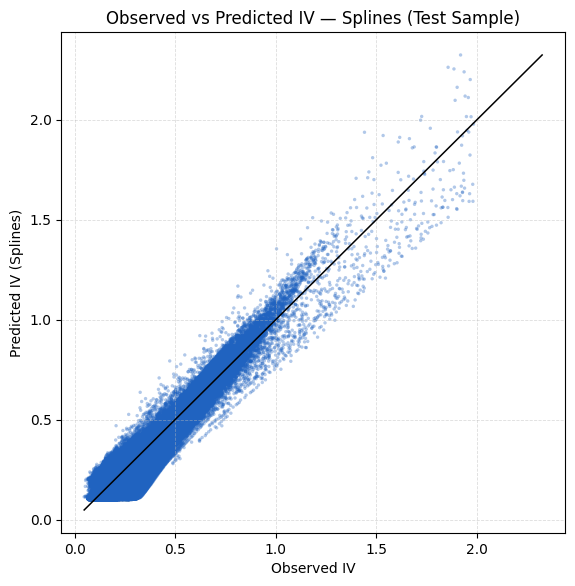

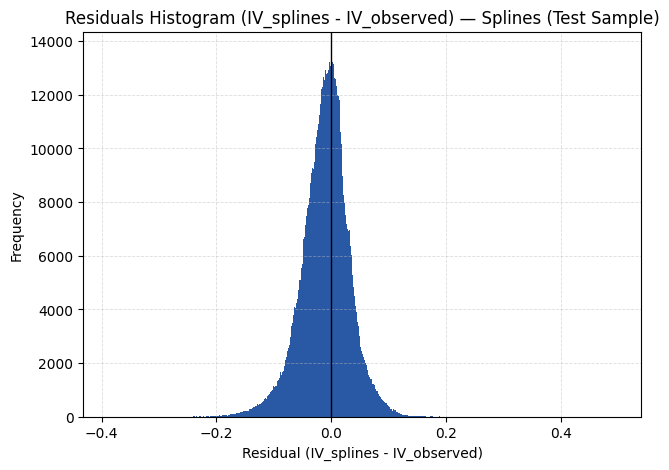

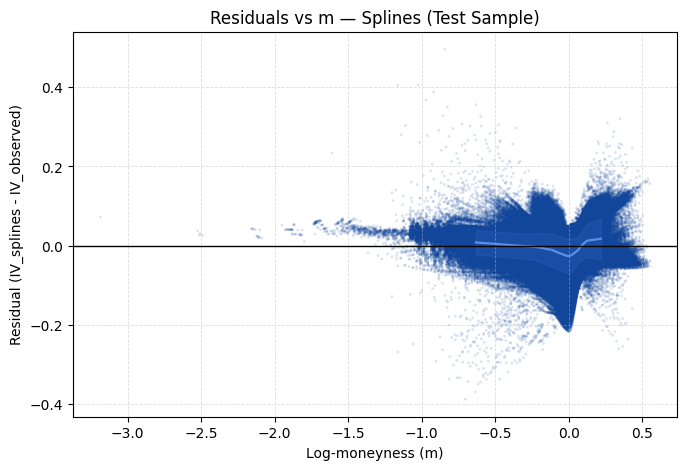

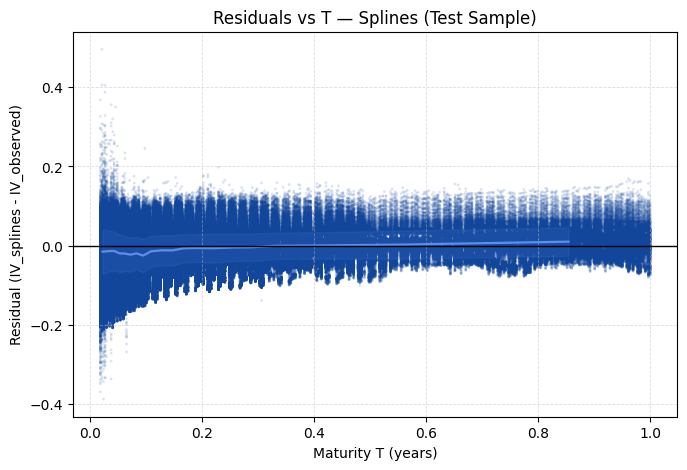

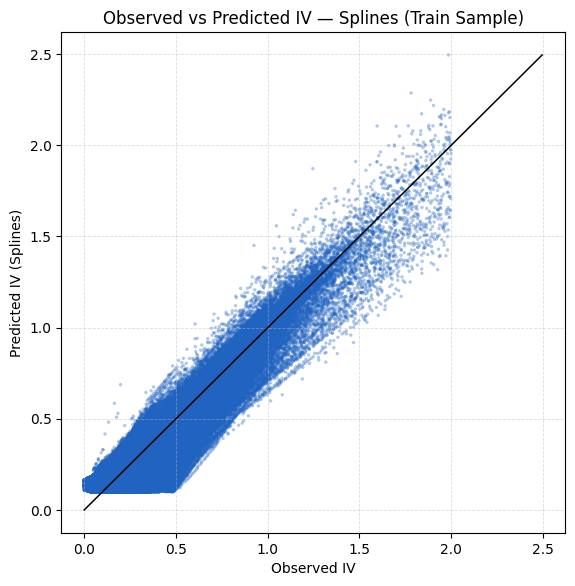

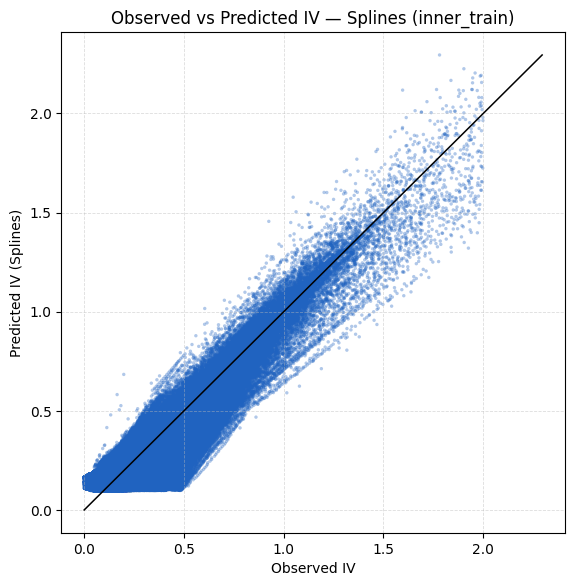

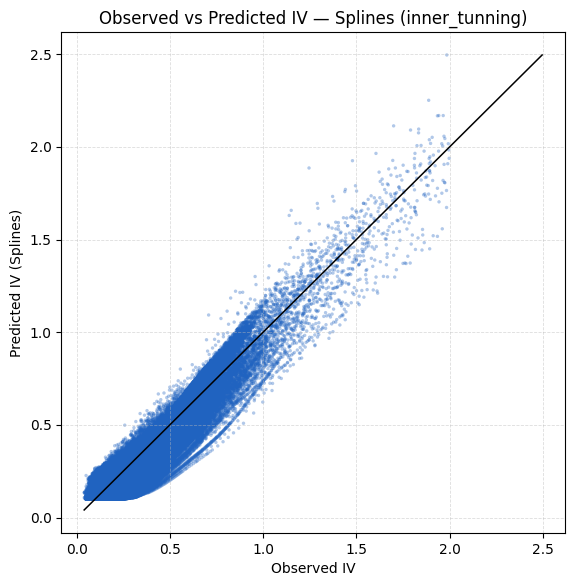

,model,split,analysis,variant,n_obs,RMSE,MAE,MedAE,R2,Bias
0,Splines,test_puro,geral,train_full,1292514,0.043071,0.032363,0.024943,0.863330,-1.025609e-02
1,Splines,train_full,especifica,train_full,7505238,0.045872,0.032741,0.024970,0.865101,3.102242e-17
2,Splines,Test Sample,geral,train_full,1292514,0.043071,0.032363,0.024943,0.863330,-1.025609e-02
3,Splines,Train Sample,especifica,train_full,7505238,0.045872,0.032741,0.024970,0.865101,3.102242e-17
4,Splines,inner_train,especifica,inner_training,5970843,0.047797,0.034094,0.025789,0.852969,-4.021318e-17
5,Splines,inner_tunning,especifica,inner_training,1534395,0.037978,0.027697,0.021191,0.908160,5.369771e-03


,model,split,analysis,variant,n_obs,RMSE,MAE,MedAE,R2,Bias
0,Splines,test_puro,geral,train_full,1292514,0.043071,0.032363,0.024943,0.863330,-1.025609e-02
1,Splines,train_full,especifica,train_full,7505238,0.045872,0.032741,0.024970,0.865101,3.102242e-17
2,Splines,Test Sample,geral,train_full,1292514,0.043071,0.032363,0.024943,0.863330,-1.025609e-02
3,Splines,Train Sample,especifica,train_full,7505238,0.045872,0.032741,0.024970,0.865101,3.102242e-17
4,Splines,inner_train,especifica,inner_training,5970843,0.047797,0.034094,0.025789,0.852969,-4.021318e-17


In [11]:
# --- chamar a função run_avaliacoes ---
res_splines = run_avaliacoes(
    df_inner_train=df_inner_train_pred,   # contém ivs_modelo
    df_inner_tunning=df_inner_tunning_pred,  # melhor do tuning (ou df_valid_pred do train_splines)
    df_train_full=df_train_full_pred,
    df_test_puro=df_test_puro_pred,
    model="Splines",
    DIR_TABELAS=DIR_TABELAS,
    DIR_GRAFICOS=DIR_GRAFICOS,
    scatter_mode="all",
    max_points_scatter=250_000,
    dpi=160,
    display_in_notebook=True
)

res_splines["globais_df"].head()

Visualização Gráfica

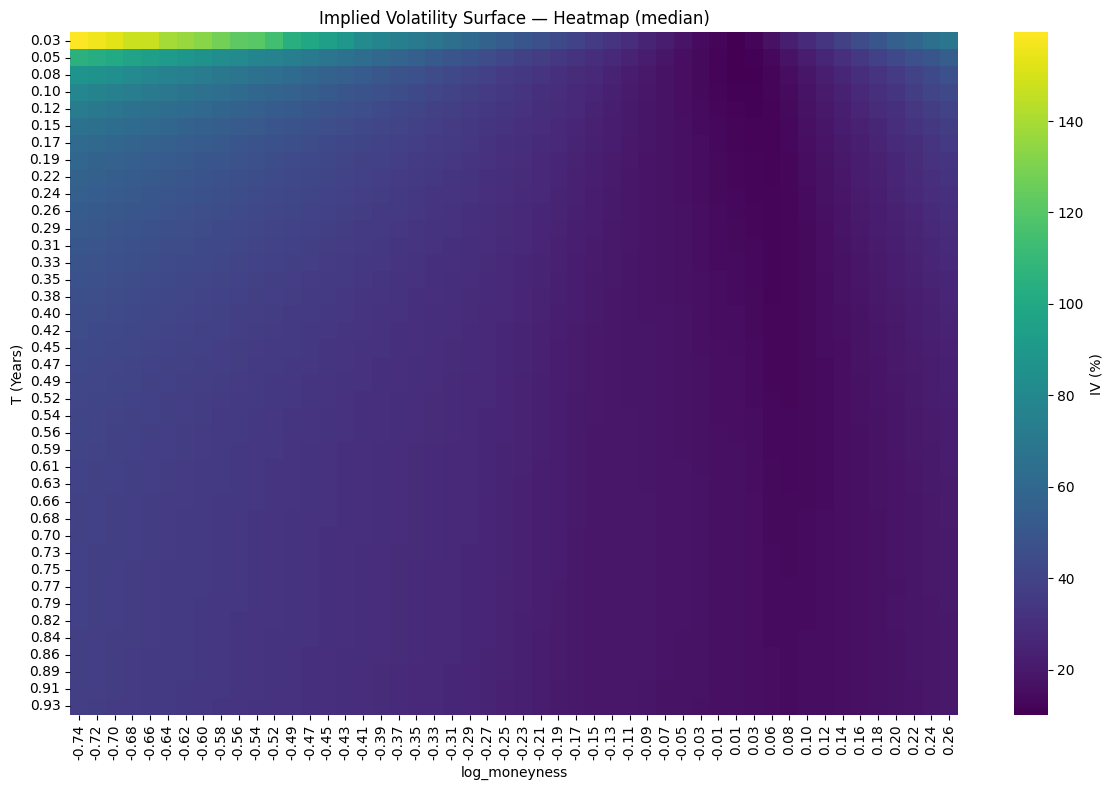

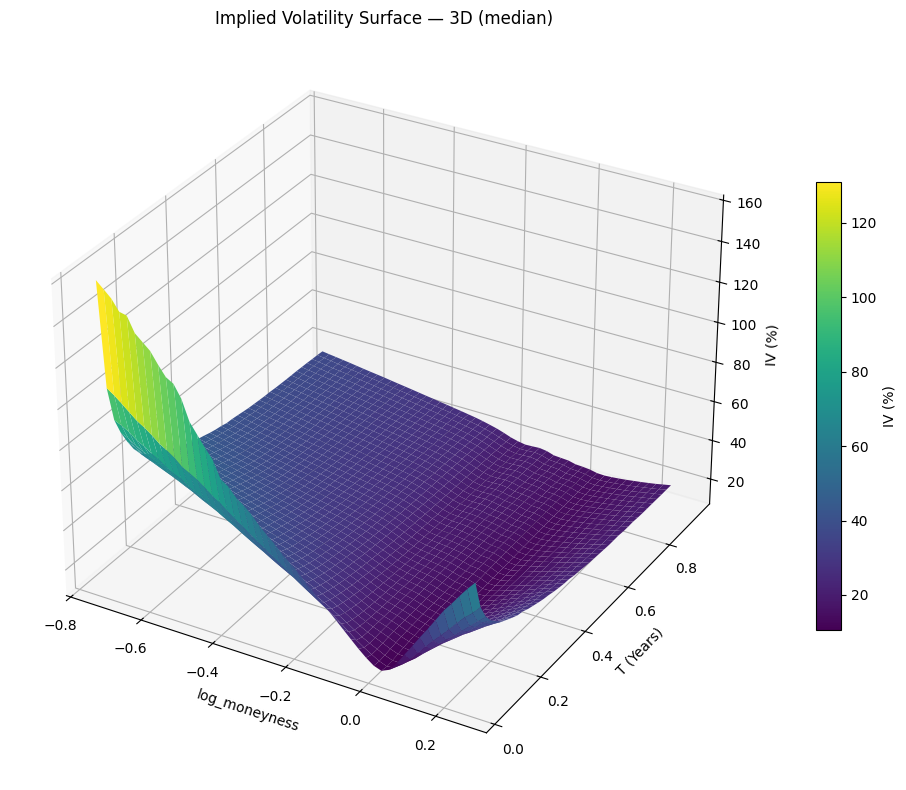

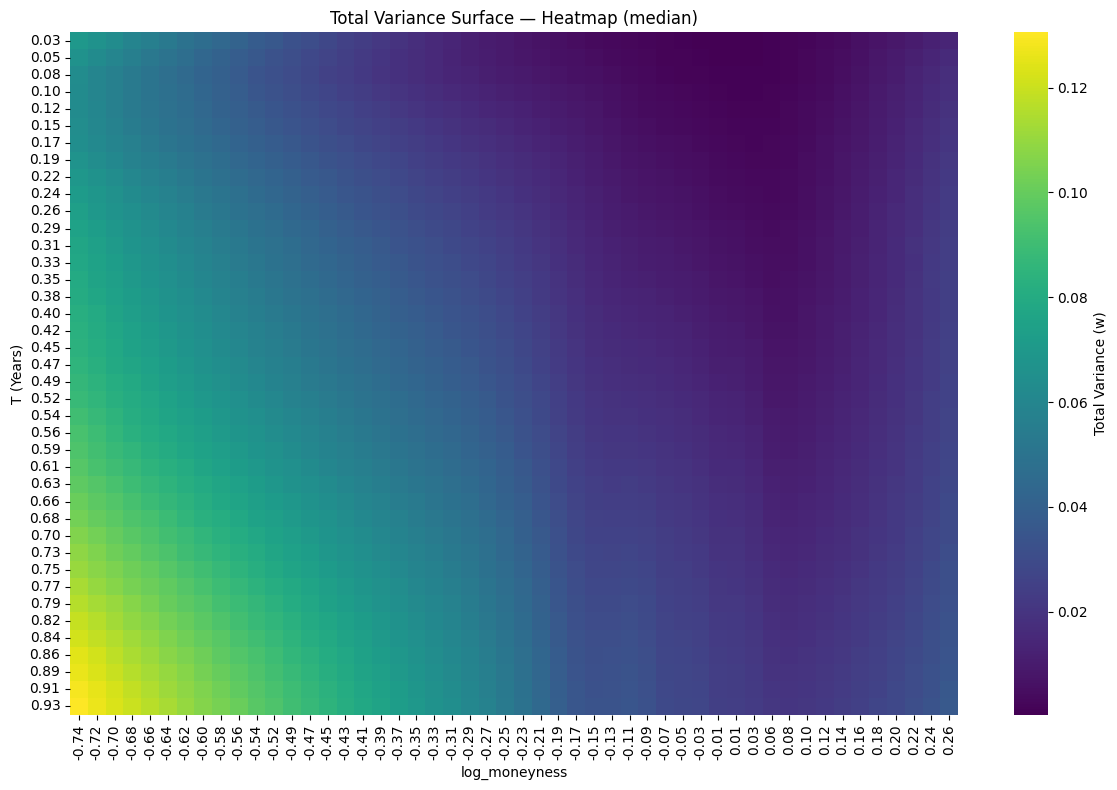

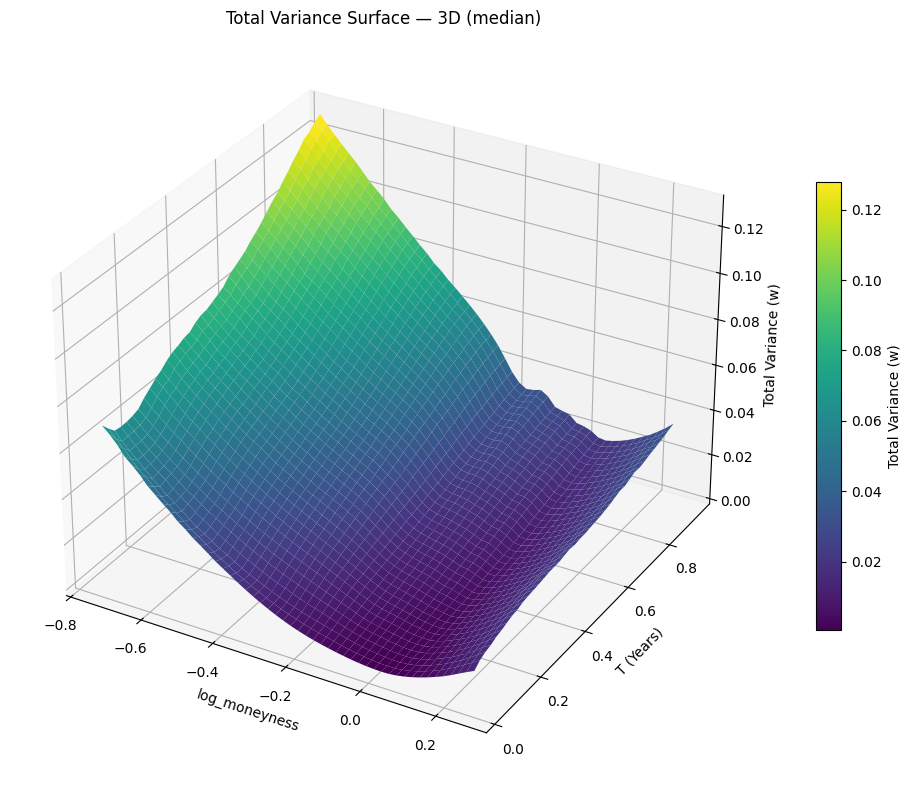

In [12]:
# 1) IVS e Superfícies de Variância do Modelo 
plot_ivs_and_variance_surfaces(
    df_test_puro_pred,
    x_col="log_moneyness", y_col="T", z_col="ivs_modelo",
    agg="median",
    nbins_x=50, nbins_y=40,
    save_dir=DIR_GRAFICOS, filename_prefix="Splines"
)